## Double Momentum Strategy

In [75]:
import csv
import json
from datetime import datetime, timedelta, timezone
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.ar_model import AutoReg

from ctrader_open_api import Client, Protobuf, TcpProtocol, EndPoints
import ctrader_open_api.messages.OpenApiMessages_pb2 as OA
import ctrader_open_api.messages.OpenApiModelMessages_pb2 as OAModel
from twisted.internet import reactor



In [33]:
#!python Data_Retrieval.py

Downloaing data 

In [34]:
DATA_FILE = Path("data/btcusd_m1.csv")

df = pd.read_csv(DATA_FILE, parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)



Data Quality Checks

In [35]:


print("\n=== DATASET OVERVIEW ===")
print(f"Rows: {len(df):,}")
print(f"Columns: {df.columns.tolist()}")
print(f"First timestamp: {df['timestamp'].min()}")
print(f"Last timestamp:  {df['timestamp'].max()}")

print("\n=== DATA QUALITY ===")
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())
print("\nMissing values:")
print(df.isna().sum())

print("\n=== TIMESTAMP COVERAGE ===")
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
time_diff = df["timestamp"].diff()

print("Median interval:", time_diff.median())
print("Largest interval:", time_diff.max())
print("Intervals greater than 1 minute:", (time_diff > pd.Timedelta(minutes=1)).sum())

print("\n=== OHLC VALIDATION ===")
print("Close <= High:", (df["close"] <= df["high"]).all())
print("Close >= Low:", (df["close"] >= df["low"]).all())
print("High >= Low:", (df["high"] >= df["low"]).all())
print("Open within range:", ((df["open"] >= df["low"]) & (df["open"] <= df["high"])).all())

print("\n=== PRICE STATISTICS ===")
print(df[["open", "high", "low", "close"]].describe())

print("\n=== FIRST FIVE ROWS ===")
print(df.head())

print("\n=== LAST FIVE ROWS ===")
print(df.tail())

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)
df = df.set_index("timestamp")

df["price_diff"] = df["close"].diff()
df = df.dropna()


=== DATASET OVERVIEW ===
Rows: 522,933
Columns: ['timestamp', 'open', 'high', 'low', 'close', 'volume']
First timestamp: 2025-10-11 11:44:00+00:00
Last timestamp:  2026-10-11 11:43:00+00:00

=== DATA QUALITY ===
Duplicate timestamps: 0

Missing values:
timestamp    0
open         0
high         0
low          0
close        0
volume       0
dtype: int64

=== TIMESTAMP COVERAGE ===
Median interval: 0 days 00:01:00
Largest interval: 0 days 06:18:00
Intervals greater than 1 minute: 445

=== OHLC VALIDATION ===
Close <= High: True
Close >= Low: True
High >= Low: True
Open within range: True

=== PRICE STATISTICS ===
                open           high            low          close
count  522933.000000  522933.000000  522933.000000  522933.000000
mean    78796.617203   78825.956537   78767.192178   78796.588630
std     13589.786447   13594.120975   13585.410445   13589.715244
min     57802.340000   58036.350000   57723.150000   57745.520000
25%     66913.950000   66939.570000   66890.33000

In [68]:
calculate_momentum(df, 1, 20)

,open,high,low,close,volume,price_diff,momentum_1m,momentum_1h,momentum_20m
timestamp,,,,,,,,,
2025-10-11 11:45:00+00:00,112454.68,112454.68,112409.83,112410.39,204,NaN,NaN,NaN,NaN
2025-10-11 11:46:00+00:00,112416.64,112461.37,112411.47,112449.47,192,39.08,0.000348,NaN,NaN
2025-10-11 11:47:00+00:00,112450.53,112487.12,112397.39,112412.26,205,-37.21,-0.000331,NaN,NaN
2025-10-11 11:48:00+00:00,112432.77,112432.77,112341.55,112352.03,198,-60.23,-0.000536,NaN,NaN
2025-10-11 11:49:00+00:00,112361.78,112375.10,112251.14,112260.33,207,-91.70,-0.000816,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-11 11:39:00+00:00,82940.74,82970.65,82930.04,82970.65,132,31.02,0.000374,0.000969,0.000150
2026-10-11 11:40:00+00:00,82960.11,82980.72,82931.25,82947.89,130,-22.76,-0.000274,0.000704,-0.000039
2026-10-11 11:41:00+00:00,82947.60,82959.64,82933.90,82938.94,102,-8.95,-0.000108,0.000570,-0.000543


In [69]:


def calculate_momentum(
    df: pd.DataFrame,
    X: int,
    Y: int,
    price_col: str = "close",
) -> pd.DataFrame:
    """
    Calculate X-minute and Y-minute momentum.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with one-minute candles.
    X : int
        Short-term momentum lookback in minutes.
    Y : int
        Long-term momentum lookback in minutes.
    price_col : str
        Price column, e.g. 'close'.

    Returns
    -------
    pd.DataFrame
        Original data plus momentum columns, expressed as returns.
    """
    if X <= 0 or Y <= 0:
        raise ValueError("X and Y must be positive integers.")

    if not isinstance(X, int) or not isinstance(Y, int):
        raise TypeError("X and Y must be integers.")

    if price_col not in df.columns:
        raise ValueError(f"Column '{price_col}' not found.")

    result = df.copy()

    # X-minute momentum: compare with the close X rows ago.
    result[f"momentum_{X}m"] = (
        result[price_col] / result[price_col].shift(X) - 1
    )

    # Y-minute momentum: one-minute candles -> Y rows.
    result[f"momentum_{Y}m"] = (
        result[price_col]
        / result[price_col].shift(Y)
        - 1
    )

    return result


def perform_autoregressive_analysis(df: pd.DataFrame, aggregation_level: str = "1H", price_col: str = "close"):
    
    """
    Perform autoregressive analysis on the given DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with one-minute candles.
    aggregation_level : str
        Resampling frequency, e.g. '1H' for hourly.
    price_col : str
        Price column, e.g. 'close'.

    Returns
    -------
    None
        Displays ACF and PACF plots.
    """

    if price_col not in df.columns:
        raise ValueError(f"Column '{price_col}' not found.")

    # Aggregating 
    if aggregation_level == "1min":
        pass 
    else:
        df = df.resample(aggregation_level).last().dropna()

    df["close"].diff().dropna() 

    # Calculate the first difference of the price series to make it stationary
    df_diff = df[price_col].diff().dropna()

    # ACF and PACF of differenced prices
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    plot_acf(df_diff, lags=20, ax=axes[0])
    plot_pacf(df_diff, lags=20, ax=axes[1], method="ywm")

    plt.tight_layout()
    plt.show()


    # Perform Augmented Dickey-Fuller test to check for stationarity
    print("\n=== AUGMENTED DICKEY-FULLER TEST ===")

    adf_result = adfuller(df_diff)
    print("ADF Statistic:", adf_result[0])
    print("p-value:", adf_result[1])
    print("Critical Values:", adf_result[4])

    # Perform autoregressive modeling for different lag values and compare AIC and BIC
    print("\n=== AUTOREGRESSIVE MODELING ===")

    results = []

    for p in range(1, 25):
        model = AutoReg(df_diff, lags=p, trend="c") # old_names=False)
        fitted = model.fit()

        results.append({
            "lags": p,
            "AIC": fitted.aic,
            "BIC": fitted.bic,
        })

    comparison = pd.DataFrame(results).sort_values("AIC")
    print(comparison)



Examining autoregressive strucrure of closings.

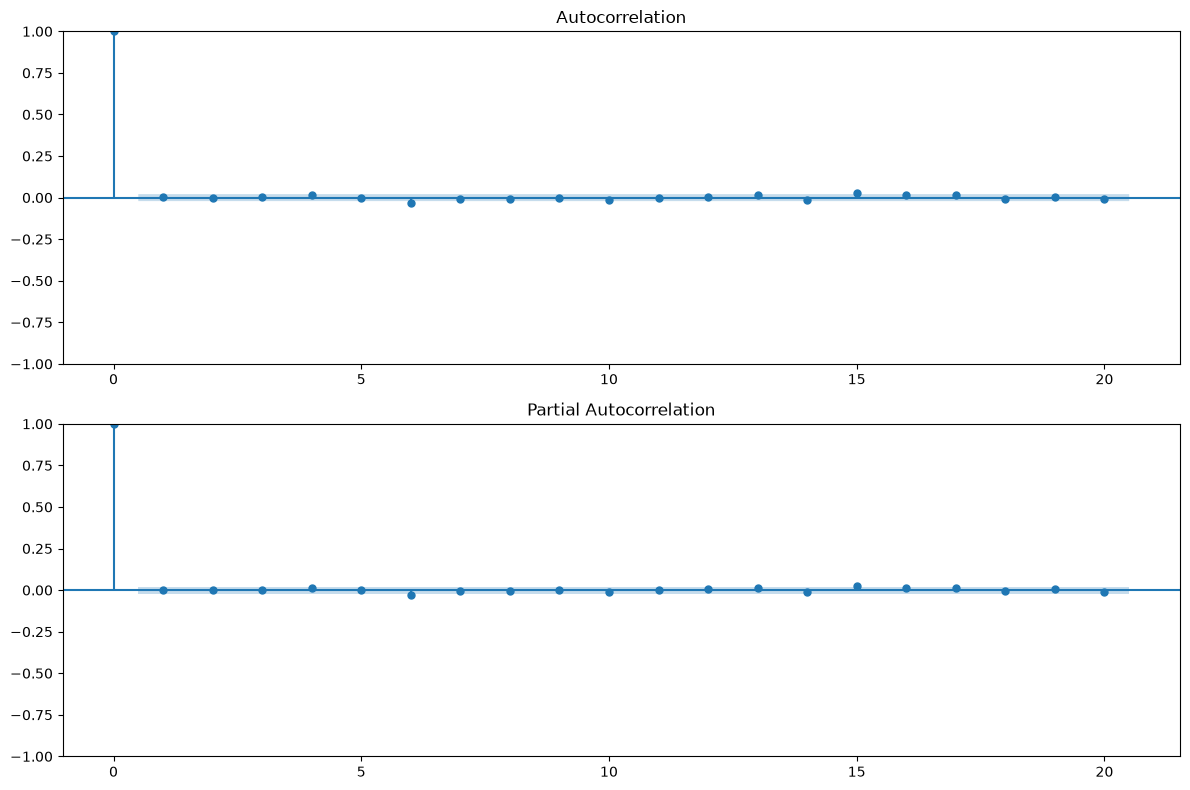


=== AUGMENTED DICKEY-FULLER TEST ===
ADF Statistic: -38.98630617594871
p-value: 0.0
Critical Values: {'1%': np.float64(-3.4310990236088363), '5%': np.float64(-2.8618710185907106), '10%': np.float64(-2.566946196227356)}

=== AUTOREGRESSIVE MODELING ===
    lags            AIC            BIC
23    24  127831.627584  128015.520409
22    23  127843.838270  128020.661163
21    22  127855.712141  128025.464872
20    21  127869.799393  128032.481731
19    20  127883.772153  128039.383869
18    19  127896.579433  128045.120298
17    18  127908.584105  128050.053888
16    17  127920.660931  128055.059404
15    16  127939.135103  128066.462036
14    15  127954.659820  128074.914983
13    14  127971.889026  128085.072190
12    13  127985.947143  128092.058079
11    12  128006.220486  128105.258963
10    11  128019.046573  128111.012363
9     10  128030.879960  128115.772833
8      9  128046.696793  128124.516520
7      8  128065.036163  128135.782515
6      7  128081.387669  128145.060416
5     

C:\Users\Computer\AppData\Local\Temp\ipykernel_15696\1102520820.py:99: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_diff)
c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates,

In [37]:
# For 1H 
perform_autoregressive_analysis(df, "1h", "close")
    

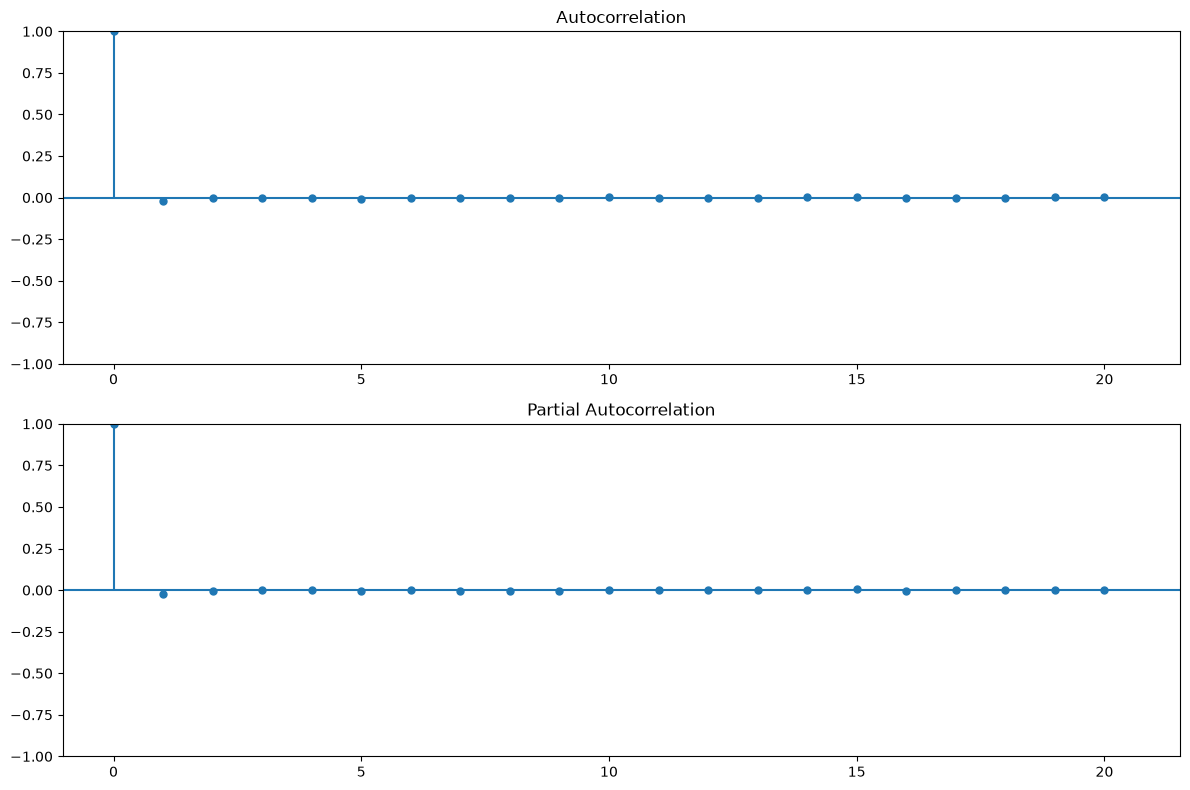


=== AUGMENTED DICKEY-FULLER TEST ===


C:\Users\Computer\AppData\Local\Temp\ipykernel_15696\1102520820.py:99: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(df_diff)
c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates,

ADF Statistic: -71.72339225925451
p-value: 0.0
Critical Values: {'1%': np.float64(-3.4303625076164748), '5%': np.float64(-2.861545528219794), '10%': np.float64(-2.566772942469364)}

=== AUTOREGRESSIVE MODELING ===


c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
c:\Users\Computer\anaconda3\envs\cTraderBot\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency

    lags           AIC           BIC
23    24  5.579119e+06  5.579409e+06
22    23  5.579129e+06  5.579409e+06
21    22  5.579150e+06  5.579418e+06
20    21  5.579172e+06  5.579429e+06
19    20  5.579180e+06  5.579426e+06
18    19  5.579193e+06  5.579427e+06
17    18  5.579201e+06  5.579425e+06
16    17  5.579210e+06  5.579422e+06
15    16  5.579219e+06  5.579420e+06
14    15  5.579235e+06  5.579425e+06
13    14  5.579260e+06  5.579438e+06
12    13  5.579268e+06  5.579436e+06
11    12  5.579278e+06  5.579434e+06
10    11  5.579285e+06  5.579430e+06
9     10  5.579294e+06  5.579428e+06
8      9  5.579302e+06  5.579425e+06
7      8  5.579315e+06  5.579426e+06
6      7  5.579327e+06  5.579428e+06
5      6  5.579350e+06  5.579439e+06
4      5  5.579360e+06  5.579438e+06
3      4  5.579386e+06  5.579453e+06
2      3  5.579398e+06  5.579453e+06
1      2  5.579407e+06  5.579452e+06
0      1  5.579422e+06  5.579456e+06


In [38]:
# For 1min 
perform_autoregressive_analysis(df, "1min", "close")

Examining relationship of momentums across different time frames.

I shall define momentum as   $M_t^{(X)} = \frac{P_t}{P_{t-X}} - 1$
 

In [39]:
df["price_diff"] = df["close"].diff()

In [ ]:


def calculate_momentum(
    df: pd.DataFrame,
    X: int,
    Y: int,
    price_col: str = "close",
) -> pd.DataFrame:
    """
    Calculate X-minute and Y-minute momentum.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with one-minute candles.
    X : int
        Short-term momentum lookback in minutes.
    Y : int
        Long-term momentum lookback in minutes.
    price_col : str
        Price column, e.g. 'close'.

    Returns
    -------
    pd.DataFrame
        Original data plus momentum columns, expressed as returns.
    """
    if X <= 0 or Y <= 0:
        raise ValueError("X and Y must be positive integers.")

    if not isinstance(X, int) or not isinstance(Y, int):
        raise TypeError("X and Y must be integers.")

    if price_col not in df.columns:
        raise ValueError(f"Column '{price_col}' not found.")

    result = df.copy()

    # X-minute momentum: compare with the close X rows ago.
    result[f"momentum_{X}m"] = (
        result[price_col] / result[price_col].shift(X) - 1
    )

    # Y-minute momentum: one-minute candles -> Y rows.
    result[f"momentum_{Y}m"] = (
        result[price_col]
        / result[price_col].shift(Y)
        - 1
    )

    return result


In [85]:
def momentum_analysis(df: pd.DataFrame, X: int = 1, Y: int = 1):
    """
    Perform momentum analysis on the given DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame with one-minute candles.
    X : int
        Short-term momentum lookback in minutes.
    Y : int
        Long-term momentum lookback in minutes.

    Returns
    -------
    float
        The mean price difference when both momentums are positive.
    """
    df_momentum = calculate_momentum(df, X=X, Y=Y)
    
    df_momentum["both_positive"] = (df_momentum[f"momentum_{X}m"] > 0) & (df_momentum[f"momentum_{Y}m"] > 0)
    df_momentum["both_negative"] = (df_momentum[f"momentum_{X}m"] < 0) & (df_momentum[f"momentum_{Y}m"] < 0)
    

    #print(f"\n=== MOMENTUM ANALYSIS (X={X}m, Y={Y}h) ===")
    #print(df_momentum["price_diff"].groupby(df_momentum["both_positive"]).mean())
    
    # returning the mean price difference when both momentums are positive
    return df_momentum["price_diff"].groupby(df_momentum["both_positive"]).mean().iloc[1], df_momentum["price_diff"].groupby(df_momentum["both_negative"]).mean().iloc[1]

In [71]:
momentum_analysis(df, 1, 20)

np.float64(34.159795981934295)

In [86]:
short_timeframes = [1, 2, 3]  # in minutes
long_timeframes = [5, 7, 10, 20, 30, 45, 60, 90, 120, 240, 360]  # in minutes

mean_returns_both_pos = np.zeros((len(short_timeframes), len(long_timeframes)))
mean_returns_both_neg = np.zeros((len(short_timeframes), len(long_timeframes)))

for i, X in enumerate(short_timeframes):
    for j, Y in enumerate(long_timeframes):
        mean_returns_both_pos[i, j], mean_returns_both_neg[i, j] = momentum_analysis(df, X, Y)
        

Heatmap for Mean Returns When Both Momentums Are Positive


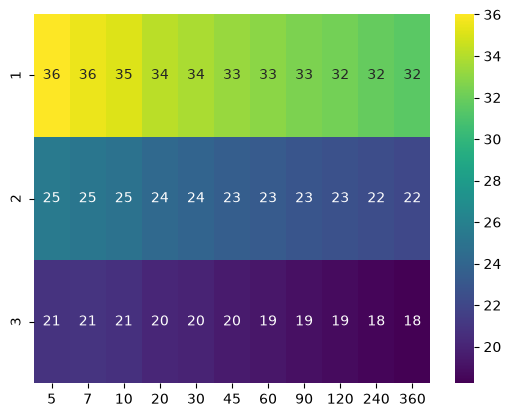




Heatmap for Mean Returns When Both Momentums Are Negative


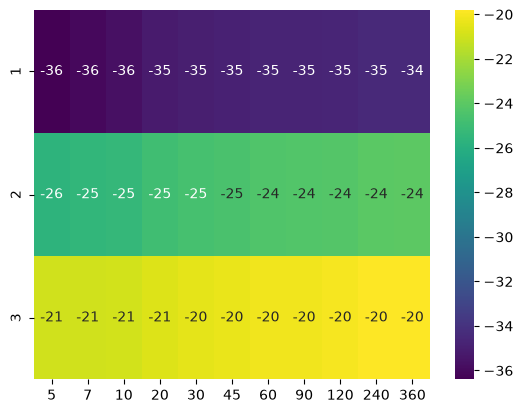

In [90]:
print("Heatmap for Mean Returns When Both Momentums Are Positive")

sns.heatmap(
    mean_returns_both_pos,
    cmap="viridis",
    xticklabels=long_timeframes,
    yticklabels=short_timeframes,
    annot=True  # Display values inside cells (optional)
)
plt.show()

print("\n\n")  
print("Heatmap for Mean Returns When Both Momentums Are Negative")

sns.heatmap(
    mean_returns_both_neg,
    cmap="viridis",
    xticklabels=long_timeframes,
    yticklabels=short_timeframes,
    annot=True  # Display values inside cells (optional)
)
plt.show()
